In [1]:
import pandas as pd
import numpy as np
import re
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

In [2]:
# ============================================================
# 1. CONFIG
# ============================================================
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"

housing_path = DATA_DIR / "Master_Housing_Dataset_V2.xlsx"

# Output folders for figures and tables
output_folder = PROJECT_ROOT / "output" / "eda_housing"
figures_folder = output_folder / "figures"
tables_folder = output_folder / "tables"
figures_folder.mkdir(parents=True, exist_ok=True)
tables_folder.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. RESEARCH PARAMETERS
# ============================================================
CITIES = [
    "Toronto",
    "Vancouver",
    "Montreal"
]
BEDROOM_GROUPS = [
    "Studio",
    "1 bedroom",
    "2 bedrooms",
    "3 bedrooms",
    "4+ bedrooms"
]
SOURCES = [
    "Rentals.ca",
    "Realtor.ca"
]
RATING_COLUMNS = [
    "rating_shopping",
    "rating_groceries",
    "rating_restaurants",
    "rating_cafes",
    "rating_transit",
    "rating_parks",
    "rating_wellness"
]

# Colors used in every chart
CITY_COLORS = {"Toronto": "#1f77b4",
               "Vancouver": "#2ca02c",
               "Montreal": "#d62728"}
SOURCE_COLORS = {"Rentals.ca": "#8172b3",
                 "Realtor.ca": "#937860"}

# Square feet below this value are data entry errors (0 and 2 in the dataset)
MIN_SQUARE_FEET = 100

# Charts are cut at this monthly rent so one or two luxury listings do not flatten them.
# The listings above this value are still included in every table.
RENT_AXIS_LIMIT = 10000

# Minimum number of listings needed in a group to run a statistical test
MIN_GROUP_SIZE = 5

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [3]:
# ============================================================
# 3. HELPER FUNCTIONS
# ============================================================

#function to inspect a dataset
def inspect_dataset(df, dataset_name):
    print(f"\n--- {dataset_name} ---")
    print("Rows:", len(df))
    print("Columns:", len(df.columns))
    print("Exact duplicate rows:", df.duplicated().sum())

    missing = (df.isna().sum().to_frame("missing_count"))
    missing["missing_percentage"] = (missing["missing_count"] / len(df) * 100).round(2)
    missing["dtype"] = df.dtypes.astype(str)
    missing["unique_values"] = df.nunique()
    display(missing.sort_values("missing_percentage", ascending=False))
    return missing

#function to identify the website of each listing from its url
def identify_source(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip().lower()
    if "rentals.ca" in value:
        return "Rentals.ca"
    elif "realtor.ca" in value:
        return "Realtor.ca"
    return np.nan

#function to group the number of bedrooms
def group_bedrooms(value):
    if pd.isna(value):
        return np.nan
    if value == 0:
        return "Studio"
    elif value == 1:
        return "1 bedroom"
    elif value == 2:
        return "2 bedrooms"
    elif value == 3:
        return "3 bedrooms"
    return "4+ bedrooms"

#function to summarize the monthly rent for any grouping
def rent_summary(df, group_columns):
    summary = (df.groupby(group_columns, observed=True)["monthly_rent_cad"]
               .agg(total_listings = "count",
                    median_rent = "median",
                    mean_rent = "mean",
                    q1_rent = lambda s: s.quantile(0.25),
                    q3_rent = lambda s: s.quantile(0.75),
                    min_rent = "min",
                    max_rent = "max"))
    summary["iqr_rent"] = summary["q3_rent"] - summary["q1_rent"]
    return summary.round(0)

#function to flag outliers with the 1.5 x IQR rule
def flag_outliers(rents):
    q1 = rents.quantile(0.25)
    q3 = rents.quantile(0.75)
    iqr = q3 - q1
    return (rents < q1 - 1.5 * iqr) | (rents > q3 + 1.5 * iqr)

#function to run a Kruskal-Wallis test between the groups of one column
def kruskal_test(df, group_column, comparison_name):
    result = {"comparison": comparison_name,
              "groups": 0,
              "total_listings": len(df),
              "h_statistic": np.nan,
              "p_value": np.nan}

    samples = []
    for group_name, group in df.groupby(group_column, observed=True):
        # Skip groups that are too small to compare
        if len(group) >= MIN_GROUP_SIZE:
            samples.append(group["monthly_rent_cad"].to_numpy())

    result["groups"] = len(samples)
    if len(samples) < 2:
        return result

    h_statistic, p_value = stats.kruskal(*samples)
    result["h_statistic"] = round(h_statistic, 2)
    result["p_value"] = p_value
    return result

#function to show rents as $2,500 in the chart axis
def format_dollars(value, position):
    return f"${value:,.0f}"

dollar_format = mtick.FuncFormatter(format_dollars)

#function to save a figure in the output folder
def save_figure(file_name):
    plt.tight_layout()
    plt.savefig(figures_folder / file_name, dpi=200, bbox_inches="tight")
    plt.show()

#function to save a table in the output folder
def save_table(table, file_name, index=True):
    table.to_csv(tables_folder / file_name, index=index, encoding="utf-8-sig")

In [4]:
# ============================================================
# 4. LOAD DATASET
# ============================================================
housing_raw = pd.read_excel(housing_path)

# The column names in the file are saved with quotes ('city'), so they are removed here
housing_raw.columns = [str(column).strip().strip("'") for column in housing_raw.columns]

print("Housing shape: ", housing_raw.shape)
display(housing_raw.head())

Housing shape:  (313, 21)


,id,title,city,province,address,property_type,building_type,monthly_rent_cad,monthly,bedrooms,bathrooms,square_feet,rating_shopping,rating_groceries,rating_restaurants,rating_cafes,rating_transit,rating_parks,rating_wellness,url,cost_bed_bath_threshold
0,1,205 Manning Avenue,Toronto,ON,"205 Manning Ave, Toronto, ON M6J 0E2",Single Family,Apartment,2050,YES,2,1,850,9.00,10.00,9.00,10.00,9.00,10.00,10.00,https://rentals.ca/toronto/205-manning-avenue-...,True
1,2,306 Palmerston Avenue,Toronto,ON,"306 Palmerston Blvd, Toronto, ON M6G 2N6",Single Family,Apartment,2300,YES,2,1,850,9.00,10.00,9.00,10.00,9.00,10.00,10.00,https://rentals.ca/toronto/306-palmerston-avenue,True
2,3,214 Bathurst Street,Toronto,ON,"214 Bathurst St, Toronto, ON M5T 2R9",Single Family,Apartment,3495,YES,2,1,1101,9.00,10.00,9.00,10.00,9.00,10.00,10.00,https://rentals.ca/toronto/214-bathurst-street...,True
3,4,390 Palmerston Boulevard,Toronto,ON,"390 Palmerston Blvd, Toronto, ON M6G 2N6",Single Family,House,2995,YES,1,1,613,9.00,10.00,9.00,10.00,9.00,10.00,10.00,https://rentals.ca/toronto/390-palmerston-boul...,True
4,5,517 Kingston Road,Toronto,ON,"517 Kingston Rd, Toronto, ON M4L 1V5",Single Family,Loft,3600,YES,2,2,1050,9.00,10.00,9.00,9.00,9.00,10.00,10.00,https://rentals.ca/toronto/517-kingston-road-i...,True


In [5]:
structure_report = inspect_dataset(housing_raw, "Master Housing Dataset")
save_table(structure_report, "01_structure_report.csv")

print("Duplicate IDs:", housing_raw["id"].duplicated().sum())
print("Duplicate URLs:", housing_raw["url"].duplicated().sum())
print("Repeated addresses (different units in the same building):", housing_raw["address"].duplicated().sum())

print("\nRows by city:")
display(housing_raw["city"].value_counts(dropna=False))

print("\nRows by province:")
display(housing_raw["province"].value_counts(dropna=False))

print("\nRows by property type:")
display(housing_raw["property_type"].value_counts(dropna=False))

print("\nRows by building type:")
display(housing_raw["building_type"].value_counts(dropna=False))

print("\nRows by number of bedrooms:")
display(housing_raw["bedrooms"].value_counts(dropna=False).sort_index())

print("\nRows by number of bathrooms:")
display(housing_raw["bathrooms"].value_counts(dropna=False).sort_index())

# Columns with only one value do not add information to the analysis
constant_columns = [column for column in housing_raw.columns if housing_raw[column].nunique() == 1]
print("\nColumns with only one value:", constant_columns)

print("\nNumeric summary:")
display(housing_raw[["monthly_rent_cad", "bedrooms", "bathrooms", "square_feet"]].describe().round(2))


--- Master Housing Dataset ---
Rows: 313
Columns: 21
Exact duplicate rows: 0


,missing_count,missing_percentage,dtype,unique_values
id,0,0.00,int64,313
square_feet,0,0.00,int64,153
url,0,0.00,str,313
rating_wellness,0,0.00,float64,41
rating_parks,0,0.00,float64,31
rating_transit,0,0.00,float64,25
rating_cafes,0,0.00,float64,35
rating_restaurants,0,0.00,float64,33
rating_groceries,0,0.00,float64,32
rating_shopping,0,0.00,float64,29


Duplicate IDs: 0
Duplicate URLs: 0
Repeated addresses (different units in the same building): 6

Rows by city:


city
Vancouver    116
Toronto      114
Montreal      83
Name: count, dtype: int64


Rows by province:


province
BC    116
ON    114
QC     83
Name: count, dtype: int64

... (6 outputs left out)


Rows by number of bathrooms:


bathrooms
1    204
2     82
3     16
4      8
6      2
8      1
Name: count, dtype: int64


Columns with only one value: ['monthly', 'cost_bed_bath_threshold']

Numeric summary:


,monthly_rent_cad,bedrooms,bathrooms,square_feet
count,313.00,313.00,313.00,313.00
mean,"3,105.04",1.89,1.50,950.20
std,"2,313.08",1.13,0.88,669.71
min,850.00,0.00,1.00,0.00
25%,"1,970.00",1.00,1.00,600.00
50%,"2,600.00",2.00,1.00,800.00
75%,"3,495.00",2.00,2.00,"1,100.00"
max,"30,000.00",7.00,8.00,"7,100.00"


In [6]:
# ============================================================
# 5. PREPARE DATASET FOR THE EDA
# ============================================================
housing = housing_raw.copy()

### Removing columns with only one value
housing = housing.drop(columns=constant_columns, errors="ignore")

### Creating helper columns
# Website where the listing was collected
housing["source"] = housing["url"].apply(identify_source)

# Square feet below the minimum are data entry errors, so they are set as missing
invalid_square_feet = housing["square_feet"] < MIN_SQUARE_FEET
print("Listings with invalid square feet:", invalid_square_feet.sum())
housing["square_feet"] = housing["square_feet"].where(~invalid_square_feet)

# Monthly rent per square foot (only for listings with valid square feet)
housing["rent_per_square_foot"] = housing["monthly_rent_cad"] / housing["square_feet"]

# Number of bedrooms grouped in five categories
housing["bedroom_group"] = housing["bedrooms"].apply(group_bedrooms)

# Building types with very few listings are grouped as Other
housing["building_group"] = housing["building_type"].where(housing["building_type"].isin(["Apartment", "House"]), "Other")

# Rent paid in one year
housing["annual_rent_cad"] = housing["monthly_rent_cad"] * 12

# Keep the same order of cities, bedrooms and sources in every table and chart
housing["city"] = pd.Categorical(housing["city"], categories=CITIES, ordered=True)
housing["bedroom_group"] = pd.Categorical(housing["bedroom_group"], categories=BEDROOM_GROUPS, ordered=True)
housing["source"] = pd.Categorical(housing["source"], categories=SOURCES, ordered=True)

print("Listings without a city in the CITIES list:", housing["city"].isna().sum())
print("Listings without a known source:", housing["source"].isna().sum())

# Summary of the records used in the EDA
eda_sample_summary = pd.DataFrame({"Metric": ["Listings in the dataset",
                                              "Listings used in the EDA",
                                              "Listings with valid square feet",
                                              "Listings above the chart limit"],
                                   "Value": [len(housing_raw),
                                             len(housing),
                                             housing["square_feet"].notna().sum(),
                                             (housing["monthly_rent_cad"] > RENT_AXIS_LIMIT).sum()]})
display(eda_sample_summary)
save_table(eda_sample_summary, "02_eda_sample_summary.csv", index=False)

Listings with invalid square feet: 7
Listings without a city in the CITIES list: 0
Listings without a known source: 0


,Metric,Value
0,Listings in the dataset,313
1,Listings used in the EDA,313
2,Listings with valid square feet,306
3,Listings above the chart limit,3


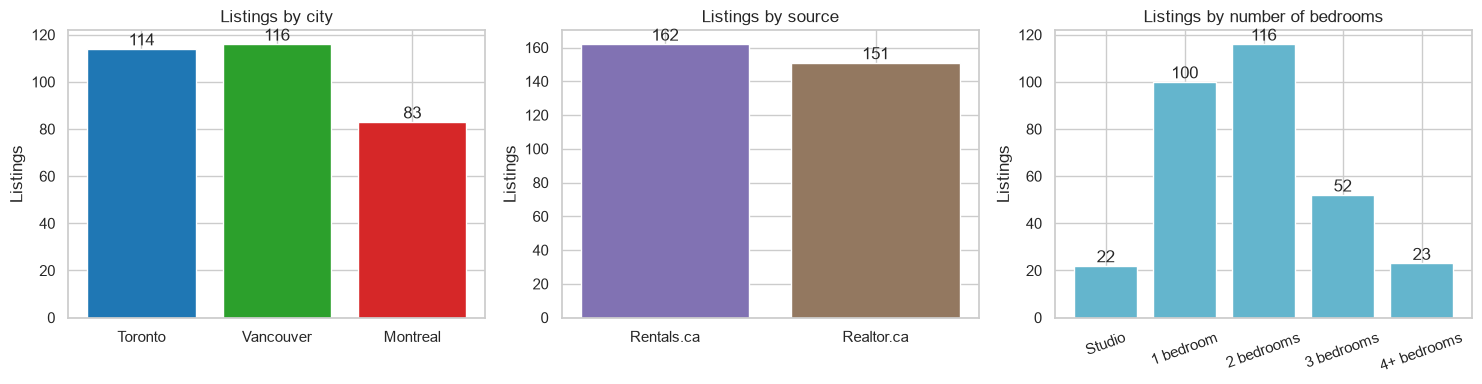

bedroom_group,Studio,1 bedroom,2 bedrooms,3 bedrooms,4+ bedrooms,Total
city,,,,,,
Toronto,6,32,45,23,8,114
Vancouver,9,46,37,13,11,116
Montreal,7,22,34,16,4,83
Total,22,100,116,52,23,313


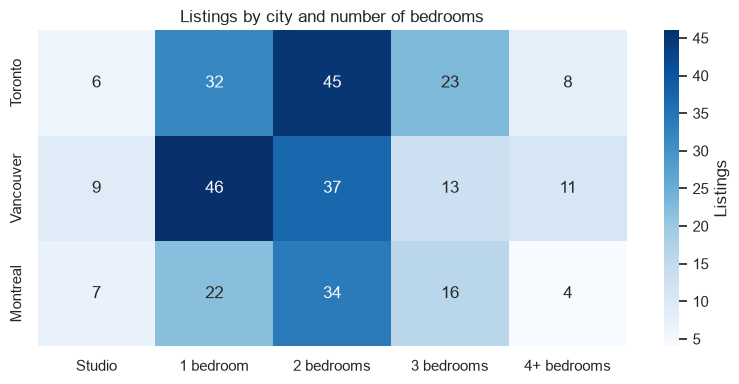

source,Rentals.ca,Realtor.ca,Total
city,,,
Toronto,54,60,114
Vancouver,56,60,116
Montreal,52,31,83
Total,162,151,313


building_type,Apartment,Duplex,Garage Suite,House,Loft,Other,Row / Townhouse,Studio,Triplex,Total
city,,,,,,,,,,
Toronto,78,3,0,18,4,3,4,2,2,114
Vancouver,96,1,1,15,0,0,2,1,0,116
Montreal,80,0,0,1,0,0,0,2,0,83
Total,254,4,1,34,4,3,6,5,2,313


In [7]:
# ============================================================
# 6. SAMPLE COMPOSITION
# ============================================================

# --------------COUNTS BY CITY, SOURCE AND BEDROOMS-----------------
city_counts = housing["city"].value_counts().reindex(CITIES)
source_counts = housing["source"].value_counts().reindex(SOURCES)
bedroom_counts = housing["bedroom_group"].value_counts().reindex(BEDROOM_GROUPS)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(city_counts.index, city_counts.values, color=[CITY_COLORS[city] for city in CITIES])
axes[0].set_title("Listings by city")
axes[1].bar(source_counts.index, source_counts.values, color=[SOURCE_COLORS[source] for source in SOURCES])
axes[1].set_title("Listings by source")
axes[2].bar(bedroom_counts.index, bedroom_counts.values, color="#64b5cd")
axes[2].set_title("Listings by number of bedrooms")
axes[2].tick_params(axis="x", rotation=20)

for ax in axes:
    ax.set_ylabel("Listings")
    # Write the number of listings above each bar
    for bar in ax.patches:
        ax.annotate(f"{int(bar.get_height()):,}",
                    (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom")
save_figure("01_counts_city_source_bedrooms.png")

# --------------CITY X BEDROOMS-----------------
city_bedroom_counts = pd.crosstab(housing["city"], housing["bedroom_group"], margins=True, margins_name="Total")
display(city_bedroom_counts)
save_table(city_bedroom_counts, "03_counts_city_bedrooms.csv")

plt.figure(figsize=(8, 4))
sns.heatmap(pd.crosstab(housing["city"], housing["bedroom_group"]), annot=True, fmt=",d", cmap="Blues", cbar_kws={"label": "Listings"})
plt.title("Listings by city and number of bedrooms")
plt.xlabel("")
plt.ylabel("")
save_figure("02_heatmap_counts_city_bedrooms.png")

# --------------CITY X SOURCE AND BUILDING TYPE-----------------
city_source_counts = pd.crosstab(housing["city"], housing["source"], margins=True, margins_name="Total")
display(city_source_counts)
save_table(city_source_counts, "04_counts_city_source.csv")

city_building_counts = pd.crosstab(housing["city"], housing["building_type"], margins=True, margins_name="Total")
display(city_building_counts)
save_table(city_building_counts, "05_counts_city_building_type.csv")

Rent summary:


,monthly_rent_cad,annual_rent_cad
count,313.00,313.00
mean,"3,105.04","37,260.54"
std,"2,313.08","27,757.00"
min,850.00,"10,200.00"
25%,"1,970.00","23,640.00"
50%,"2,600.00","31,200.00"
75%,"3,495.00","41,940.00"
max,"30,000.00","360,000.00"


Skewness of the monthly rent: 6.13


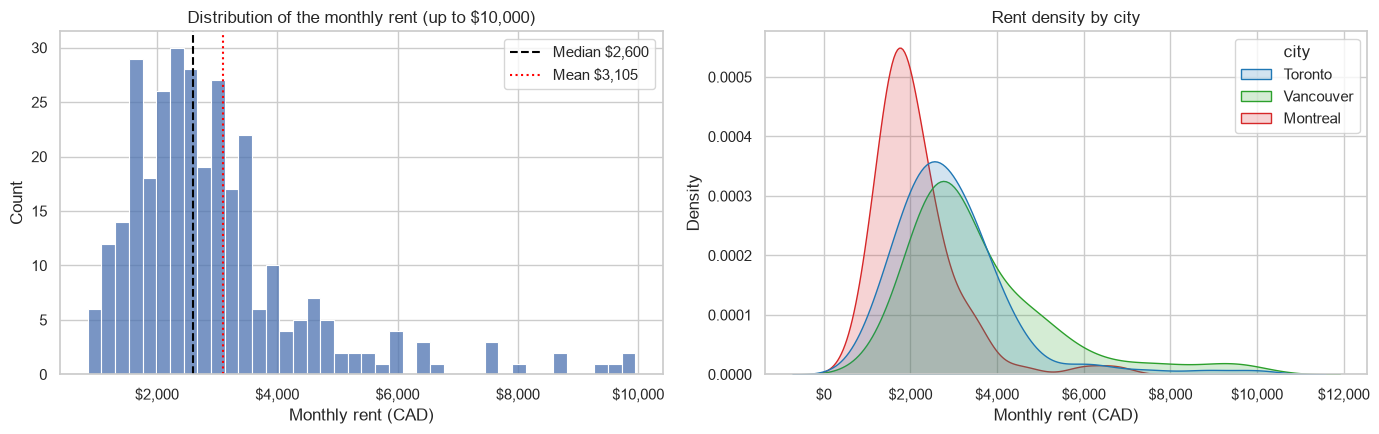

In [8]:
# ============================================================
# 7. RENT ANALYSIS
# ============================================================
# monthly_rent_cad is the main measure.
# Rents are right-skewed, so the median is used before the mean.

# --------------OVERALL DISTRIBUTION-----------------
print("Rent summary:")
display(housing[["monthly_rent_cad", "annual_rent_cad"]].describe().round(2))
print("Skewness of the monthly rent:", round(housing["monthly_rent_cad"].skew(), 2))

median_rent = housing["monthly_rent_cad"].median()
mean_rent = housing["monthly_rent_cad"].mean()
chart_data = housing.loc[housing["monthly_rent_cad"] <= RENT_AXIS_LIMIT]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(chart_data["monthly_rent_cad"], bins=40, ax=axes[0], color="#4c72b0")
axes[0].axvline(median_rent, color="black", linestyle="--", label=f"Median ${median_rent:,.0f}")
axes[0].axvline(mean_rent, color="red", linestyle=":", label=f"Mean ${mean_rent:,.0f}")
axes[0].xaxis.set_major_formatter(dollar_format)
axes[0].set_title(f"Distribution of the monthly rent (up to ${RENT_AXIS_LIMIT:,})")
axes[0].set_xlabel("Monthly rent (CAD)")
axes[0].legend()

sns.kdeplot(data=chart_data, x="monthly_rent_cad", hue="city", hue_order=CITIES, palette=CITY_COLORS,
            common_norm=False, fill=True, alpha=0.2, ax=axes[1])
axes[1].xaxis.set_major_formatter(dollar_format)
axes[1].set_title("Rent density by city")
axes[1].set_xlabel("Monthly rent (CAD)")
save_figure("03_rent_distribution.png")

In [9]:
# --------------RENT BY CITY, BEDROOMS AND CITY X BEDROOMS-----------------
rent_by_city = rent_summary(housing, "city")
rent_by_bedrooms = rent_summary(housing, "bedroom_group")
rent_by_city_bedrooms = rent_summary(housing, ["city", "bedroom_group"])

print("Rent by city:")
display(rent_by_city)

print("\nRent by number of bedrooms:")
display(rent_by_bedrooms)

print("\nRent by city and number of bedrooms:")
display(rent_by_city_bedrooms)

save_table(rent_by_city, "06_rent_by_city.csv")
save_table(rent_by_bedrooms, "07_rent_by_bedrooms.csv")
save_table(rent_by_city_bedrooms, "08_rent_by_city_bedrooms.csv")

Rent by city:


,total_listings,median_rent,mean_rent,q1_rent,q3_rent,min_rent,max_rent,iqr_rent
city,,,,,,,,
Toronto,114,"2,772.00","2,947.00","2,112.00","3,499.00",900,9950,"1,386.00"
Vancouver,116,"3,000.00","3,968.00","2,472.00","4,400.00",1350,30000,"1,928.00"
Montreal,83,"1,890.00","2,115.00","1,550.00","2,494.00",850,6750,944.00



Rent by number of bedrooms:


,total_listings,median_rent,mean_rent,q1_rent,q3_rent,min_rent,max_rent,iqr_rent
bedroom_group,,,,,,,,
Studio,22,"1,464.00","1,688.00","1,200.00","2,138.00",950,2950,938.00
1 bedroom,100,"2,200.00","2,235.00","1,688.00","2,696.00",850,4900,"1,009.00"
2 bedrooms,116,"2,798.00","3,143.00","2,200.00","3,500.00",1300,9500,"1,300.00"
3 bedrooms,52,"3,488.00","4,406.00","2,500.00","4,000.00",1550,30000,"1,500.00"
4+ bedrooms,23,"4,200.00","5,107.00","3,492.00","6,025.00",2800,9950,"2,533.00"



Rent by city and number of bedrooms:


total_listings  median_rent  mean_rent  q1_rent  \
city      bedroom_group                                                    
Toronto   Studio                      6     1,357.00   1,382.00 1,225.00   
          1 bedroom                  32     2,016.00   2,127.00 1,638.00   
          2 bedrooms                 45     2,800.00   3,002.00 2,395.00   
          3 bedrooms                 23     3,500.00   3,720.00 3,050.00   
          4+ bedrooms                 8     3,515.00   4,872.00 3,150.00   
Vancouver Studio                      9     2,390.00   2,313.00 2,100.00   
          1 bedroom                  46     2,600.00   2,636.00 2,285.00   
          2 bedrooms                 37     3,500.00   4,107.00 3,000.00   
          3 bedrooms                 13     4,900.00   8,072.00 3,500.00   
          4+ bedrooms                11     5,000.00   5,577.00 4,250.00   
Montreal  Studio                      7     1,050.00   1,149.00   995.00   
          1 bedroom                  22     1,550.00   1,556.00 1,325.00   
          2 bedrooms                 34     2,025.00   2,281.00 1,699.00   
          3 bedrooms                 16     2,494.00   2,415.00 1,923.00   
          4+ bedrooms                 4     3,492.00   4,284.00 3,463.00   

                         q3_rent  min_rent  max_rent  iqr_rent  
city      bedroom_group                                         
Toronto   Studio        1,425.00      1199      1750    200.00  
          1 bedroom     2,350.00       900      4200    712.00  
          2 bedrooms    3,300.00      1950      6000    905.00  
          3 bedrooms    3,950.00      2230      7500    900.00  
          4+ bedrooms   5,350.00      2800      9950  2,200.00  
Vancouver Studio        2,480.00      1695      2950    380.00  
          1 bedroom     2,986.00      1350      4900    701.00  
          2 bedrooms    4,790.00      1600      9500  1,790.00  
          3 bedrooms    9,900.00      2300     30000  6,400.00  
          4+ bedrooms   6,400.00      3800      9300  2,150.00  
Montreal  Studio        1,275.00       950      1500    280.00  
          1 bedroom     1,750.00       850      2100    425.00  
          2 bedrooms    2,481.00      1300      6000    782.00  
          3 bedrooms    2,571.00      1550      3750    648.00  
          4+ bedrooms   4,312.00      3400      6750    850.00

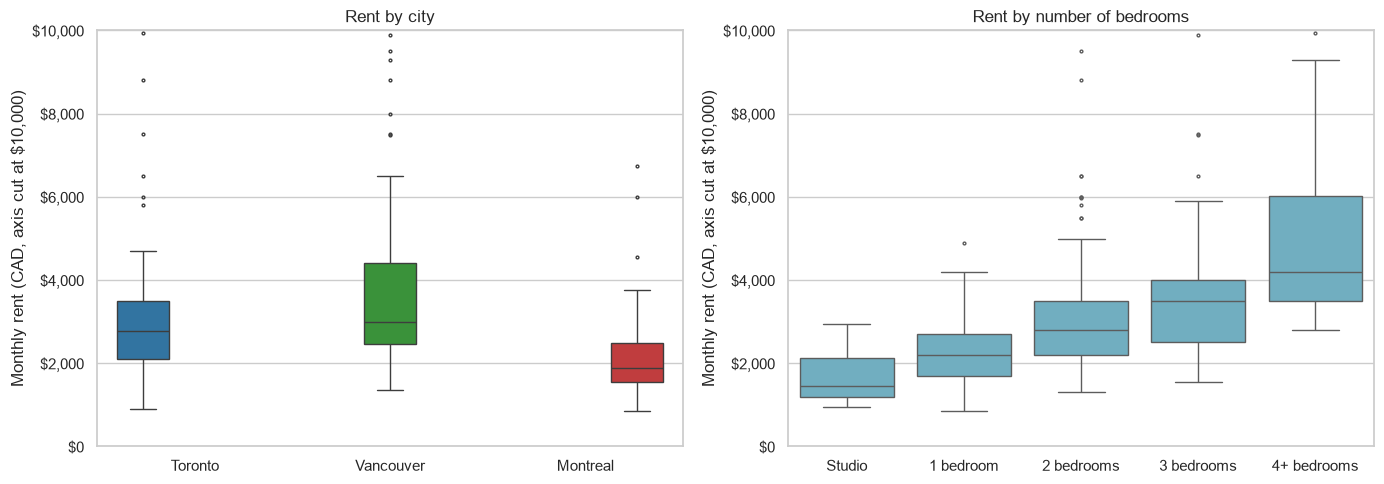

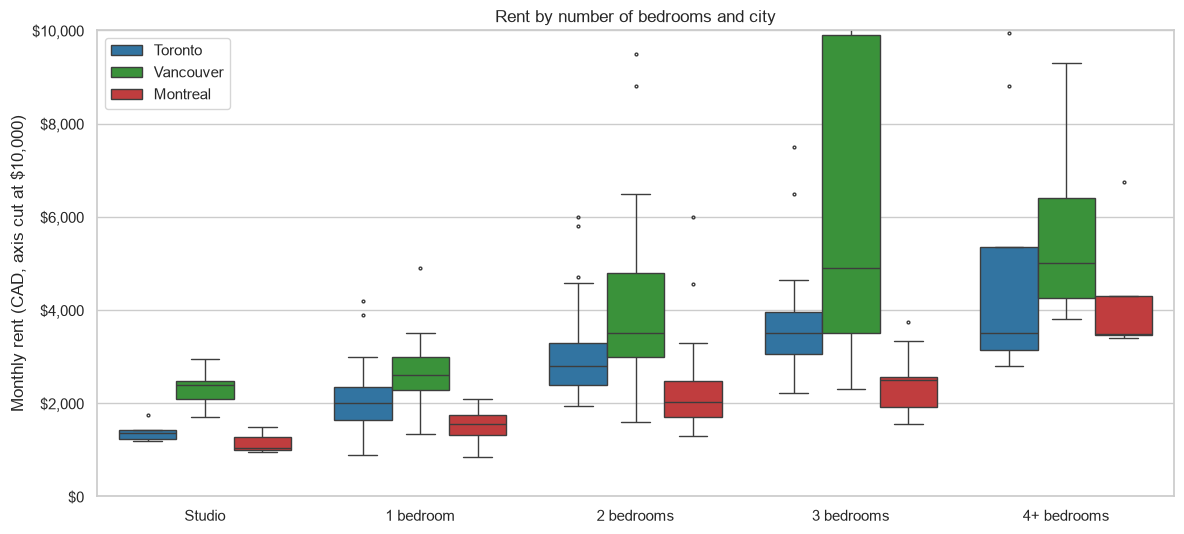

In [10]:
# --------------BOXPLOTS-----------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=housing, x="city", y="monthly_rent_cad", order=CITIES, hue="city", palette=CITY_COLORS,
            legend=False, fliersize=2, ax=axes[0])
axes[0].set_title("Rent by city")

sns.boxplot(data=housing, x="bedroom_group", y="monthly_rent_cad", order=BEDROOM_GROUPS, color="#64b5cd",
            fliersize=2, ax=axes[1])
axes[1].set_title("Rent by number of bedrooms")

for ax in axes:
    ax.set_ylim(0, RENT_AXIS_LIMIT)
    ax.yaxis.set_major_formatter(dollar_format)
    ax.set_xlabel("")
    ax.set_ylabel(f"Monthly rent (CAD, axis cut at ${RENT_AXIS_LIMIT:,})")
save_figure("04_boxplots_city_and_bedrooms.png")

plt.figure(figsize=(12, 5.5))
ax = sns.boxplot(data=housing, x="bedroom_group", y="monthly_rent_cad", hue="city", order=BEDROOM_GROUPS,
                 hue_order=CITIES, palette=CITY_COLORS, fliersize=2)
ax.set_ylim(0, RENT_AXIS_LIMIT)
ax.yaxis.set_major_formatter(dollar_format)
ax.set_title("Rent by number of bedrooms and city")
ax.set_xlabel("")
ax.set_ylabel(f"Monthly rent (CAD, axis cut at ${RENT_AXIS_LIMIT:,})")
ax.legend(title="")
save_figure("05_boxplot_bedrooms_by_city.png")

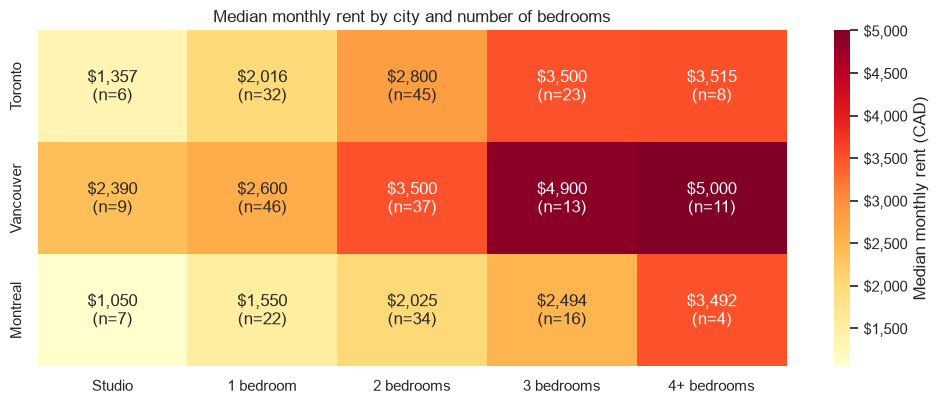

In [11]:
# --------------MEDIAN RENT HEATMAP-----------------
median_table = housing.pivot_table(index="city", columns="bedroom_group", values="monthly_rent_cad", aggfunc="median", observed=True)
count_table = housing.pivot_table(index="city", columns="bedroom_group", values="monthly_rent_cad", aggfunc="count", observed=True)

# Each cell shows the median rent and the number of listings behind it
heatmap_labels = median_table.copy().astype(object)
for city in median_table.index:
    for bedroom_group in median_table.columns:
        heatmap_labels.loc[city, bedroom_group] = (f"${median_table.loc[city, bedroom_group]:,.0f}\n"
                                                   f"(n={int(count_table.loc[city, bedroom_group])})")

plt.figure(figsize=(10, 4.2))
sns.heatmap(median_table, annot=heatmap_labels, fmt="", cmap="YlOrRd",
            cbar_kws={"label": "Median monthly rent (CAD)", "format": dollar_format})
plt.title("Median monthly rent by city and number of bedrooms")
plt.xlabel("")
plt.ylabel("")
save_figure("06_heatmap_median_rent.png")

In [12]:
# --------------OUTLIERS-----------------
# Outliers are flagged inside each city x bedroom group. They are NOT removed.
housing["rent_outlier"] = (housing.groupby(["city", "bedroom_group"], observed=True)["monthly_rent_cad"].transform(flag_outliers))

outlier_report = (housing.groupby("city", observed=True)
                  .agg(total_listings = ("title", "size"),
                       rent_outliers = ("rent_outlier", "sum")))
outlier_report["outlier_percentage"] = (outlier_report["rent_outliers"] / outlier_report["total_listings"] * 100).round(1)
display(outlier_report)
save_table(outlier_report, "09_outliers_by_city.csv")

review_columns = ["id", "source", "city", "title", "building_type", "bedrooms", "bathrooms", "square_feet", "monthly_rent_cad"]

print("Highest rents in the dataset:")
display(housing[review_columns].sort_values("monthly_rent_cad", ascending=False).head(10))

print("Lowest rents in the dataset:")
display(housing[review_columns].sort_values("monthly_rent_cad").head(10))

# --------------MEDIAN VS MEAN-----------------
# The difference between both shows how much the luxury listings pull the mean up
median_vs_mean = rent_by_city[["total_listings", "median_rent", "mean_rent"]].copy()
median_vs_mean["mean_minus_median"] = median_vs_mean["mean_rent"] - median_vs_mean["median_rent"]
display(median_vs_mean)
save_table(median_vs_mean, "10_median_vs_mean_by_city.csv")

,total_listings,rent_outliers,outlier_percentage
city,,,
Toronto,114,10,8.80
Vancouver,116,4,3.40
Montreal,83,4,4.80


Highest rents in the dataset:


,id,source,city,title,building_type,bedrooms,bathrooms,square_feet,monthly_rent_cad
268,269,Realtor.ca,Vancouver,3701 1495 Richards,Apartment,3,2,"2,520.00",30000
246,247,Realtor.ca,Vancouver,202 181 Athletes Way,Apartment,3,3,"2,998.00",14500
240,241,Realtor.ca,Vancouver,2818 89 Nelson Street,Apartment,3,4,"2,220.00",11800
53,54,Rentals.ca,Toronto,82 Gough Avenue,Apartment,5,4,"2,500.00",9950
227,228,Realtor.ca,Vancouver,Ph 199 Drake Street,Apartment,3,3,"1,982.00",9900
248,249,Realtor.ca,Vancouver,4906 1480 Howe Street,Apartment,2,3,"1,552.00",9500
80,81,Rentals.ca,Vancouver,6533 Marguerite Street,Apartment,6,8,"7,100.00",9300
204,205,Realtor.ca,Toronto,377 Hollywood Avenue,House,7,6,"3,500.00",8800
84,85,Rentals.ca,Vancouver,667 Howe Street,Apartment,2,3,"2,074.00",8800
276,277,Realtor.ca,Vancouver,4025 Granville Street,House,5,4,"4,215.00",8000


Lowest rents in the dataset:


,id,source,city,title,building_type,bedrooms,bathrooms,square_feet,monthly_rent_cad
160,161,Rentals.ca,Montreal,1290 Pins Avenue West,Apartment,1,1,500.00,850
193,194,Realtor.ca,Toronto,186 Wilfred Avenue,House,1,1,NaN,900
156,157,Rentals.ca,Montreal,4750 ON East,Apartment,0,1,400.00,950
112,113,Rentals.ca,Montreal,6860 Fielding Avenue,Apartment,0,1,400.00,995
150,151,Rentals.ca,Montreal,3840 Fontaine Street,Studio,0,1,350.00,995
110,111,Rentals.ca,Montreal,5235 Cote Saint Luc Road,Apartment,0,1,500.00,1050
152,153,Rentals.ca,Montreal,3950 Saint Kevin,Apartment,1,1,900.00,1100
33,34,Rentals.ca,Toronto,206 Langley Avenue,Apartment,1,1,200.00,1150
47,48,Rentals.ca,Toronto,2182 Gerrard Street East,Apartment,0,1,168.00,1199
118,119,Rentals.ca,Montreal,2170 Lincoln Avenue,Apartment,0,1,400.00,1200


,total_listings,median_rent,mean_rent,mean_minus_median
city,,,,
Toronto,114,"2,772.00","2,947.00",175.00
Vancouver,116,"3,000.00","3,968.00",968.00
Montreal,83,"1,890.00","2,115.00",225.00


Listings with valid square feet: 306


total_listings  median_square_feet  \
city      bedroom_group                                       
Toronto   Studio                      5              400.00   
          1 bedroom                  28              600.00   
          2 bedrooms                 43              750.00   
          3 bedrooms                 23            1,100.00   
          4+ bedrooms                 8            1,100.00   
Vancouver Studio                      9              500.00   
          1 bedroom                  46              598.00   
          2 bedrooms                 37              900.00   
          3 bedrooms                 13            1,240.00   
          4+ bedrooms                11            2,073.00   
Montreal  Studio                      7              400.00   
          1 bedroom                  22              650.00   
          2 bedrooms                 34              940.00   
          3 bedrooms                 16            1,160.50   
          4+ bedrooms                 4            2,250.00   

                         median_rent_per_square_foot  
city      bedroom_group                               
Toronto   Studio                                4.38  
          1 bedroom                             3.77  
          2 bedrooms                            3.96  
          3 bedrooms                            3.50  
          4+ bedrooms                           3.20  
Vancouver Studio                                3.99  
          1 bedroom                             4.38  
          2 bedrooms                            4.07  
          3 bedrooms                            3.80  
          4+ bedrooms                           2.17  
Montreal  Studio                                2.84  
          1 bedroom                             2.33  
          2 bedrooms                            2.22  
          3 bedrooms                            2.05  
          4+ bedrooms                           1.75

total_listings  median_square_feet  \
city      source                                           
Toronto   Rentals.ca              53              850.00   
          Realtor.ca              54              700.00   
Vancouver Rentals.ca              56              793.50   
          Realtor.ca              60              761.00   
Montreal  Rentals.ca              52              800.00   
          Realtor.ca              31              988.00   

                      median_rent_per_square_foot  
city      source                                   
Toronto   Rentals.ca                         3.54  
          Realtor.ca                         3.88  
Vancouver Rentals.ca                         3.54  
          Realtor.ca                         4.38  
Montreal  Rentals.ca                         2.11  
          Realtor.ca                         2.62

Correlation between square feet and monthly rent:


,city,total_listings,spearman_correlation,p_value
0,Toronto,107,0.63,5.31e-13
1,Vancouver,116,0.79,1.25e-25
2,Montreal,83,0.77,3.22e-17


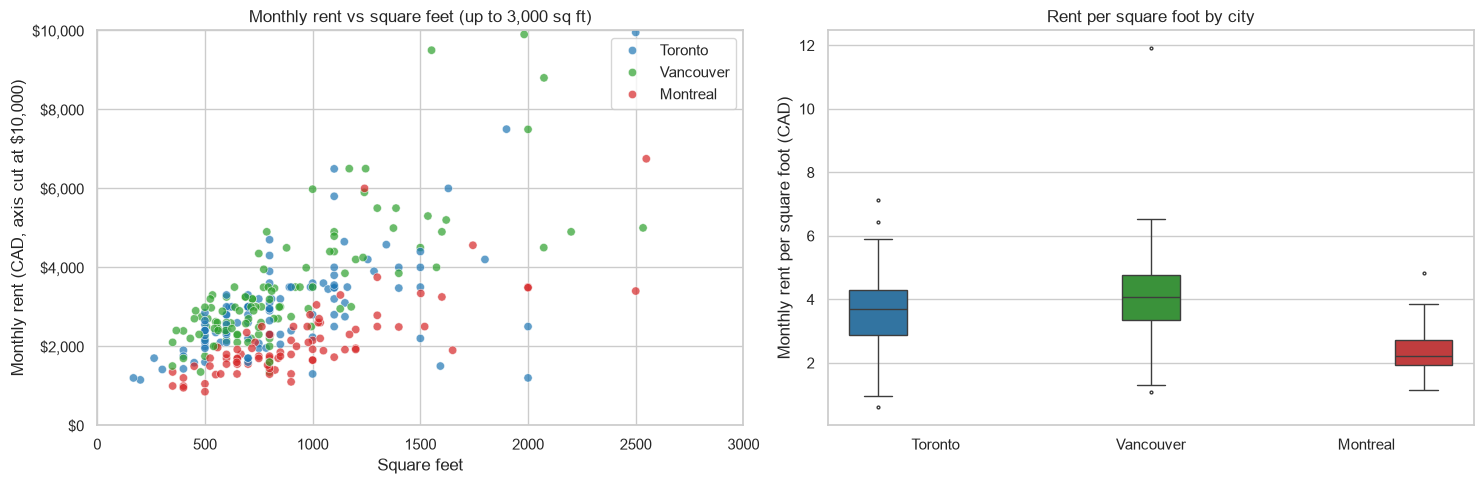

In [13]:
# ============================================================
# 8. UNIT SIZE AND RENT PER SQUARE FOOT
# ============================================================
# NOTE: For Realtor.ca, square_feet is the lower value of the range shown in the listing,
# so the size of those units is under-estimated and their rent per square foot is over-estimated.
housing_with_size = housing.dropna(subset=["square_feet"]).copy()
print("Listings with valid square feet:", len(housing_with_size))

size_by_city_bedrooms = (housing_with_size.groupby(["city", "bedroom_group"], observed=True)
                         .agg(total_listings = ("square_feet", "count"),
                              median_square_feet = ("square_feet", "median"),
                              median_rent_per_square_foot = ("rent_per_square_foot", "median")).round(2))
display(size_by_city_bedrooms)
save_table(size_by_city_bedrooms, "11_size_by_city_bedrooms.csv")

rent_per_square_foot_by_city = (housing_with_size.groupby(["city", "source"], observed=True)
                                .agg(total_listings = ("rent_per_square_foot", "count"),
                                     median_square_feet = ("square_feet", "median"),
                                     median_rent_per_square_foot = ("rent_per_square_foot", "median")).round(2))
display(rent_per_square_foot_by_city)
save_table(rent_per_square_foot_by_city, "12_rent_per_square_foot_by_city_source.csv")

# --------------RENT VS SIZE-----------------
correlation_results = []
for city in CITIES:
    city_listings = housing_with_size.loc[housing_with_size["city"] == city]
    correlation, p_value = stats.spearmanr(city_listings["square_feet"], city_listings["monthly_rent_cad"])
    correlation_results.append({"city": city,
                                "total_listings": len(city_listings),
                                "spearman_correlation": round(correlation, 2),
                                "p_value": f"{p_value:.2e}"})
size_correlation = pd.DataFrame(correlation_results)
print("Correlation between square feet and monthly rent:")
display(size_correlation)
save_table(size_correlation, "13_correlation_size_rent.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=housing_with_size, x="square_feet", y="monthly_rent_cad", hue="city", hue_order=CITIES,
                palette=CITY_COLORS, alpha=0.7, ax=axes[0])
axes[0].set_xlim(0, 3000)
axes[0].set_ylim(0, RENT_AXIS_LIMIT)
axes[0].yaxis.set_major_formatter(dollar_format)
axes[0].set_title("Monthly rent vs square feet (up to 3,000 sq ft)")
axes[0].set_xlabel("Square feet")
axes[0].set_ylabel(f"Monthly rent (CAD, axis cut at ${RENT_AXIS_LIMIT:,})")
axes[0].legend(title="")

sns.boxplot(data=housing_with_size, x="city", y="rent_per_square_foot", order=CITIES, hue="city", palette=CITY_COLORS,
            legend=False, fliersize=2, ax=axes[1])
axes[1].set_title("Rent per square foot by city")
axes[1].set_xlabel("")
axes[1].set_ylabel("Monthly rent per square foot (CAD)")
save_figure("07_rent_vs_size.png")

total_listings            median_rent           
source                      Rentals.ca Realtor.ca  Rentals.ca Realtor.ca
city      bedroom_group                                                 
Toronto   Studio                     5          1    1,414.00   1,200.00
          1 bedroom                 17         15    2,099.00   1,950.00
          2 bedrooms                17         28    3,200.00   2,725.00
          3 bedrooms                13         10    3,500.00   3,350.00
          4+ bedrooms                2          6    6,575.00   3,515.00
Vancouver Studio                     5          4    2,150.00   2,440.00
          1 bedroom                 20         26    2,595.00   2,610.00
          2 bedrooms                17         20    3,000.00   4,325.00
          3 bedrooms                 5          8    3,500.00   8,698.00
          4+ bedrooms                9          2    5,000.00   5,925.00
Montreal  Studio                     6          1    1,022.00   1,500.00
          1 bedroom                 15          7    1,525.00   1,700.00
          2 bedrooms                20         14    1,712.00   2,462.00
          3 bedrooms                 9          7    1,925.00   2,785.00
          4+ bedrooms                2          2    3,450.00   5,117.00

total_listings  median_rent  mean_rent  q1_rent  \
city      source                                                        
Toronto   Rentals.ca              54     2,798.00   3,059.00 2,009.00   
          Realtor.ca              60     2,650.00   2,846.00 2,238.00   
Vancouver Rentals.ca              56     2,998.00   3,437.00 2,475.00   
          Realtor.ca              60     3,200.00   4,464.00 2,472.00   
Montreal  Rentals.ca              52     1,700.00   1,816.00 1,456.00   
          Realtor.ca              31     2,425.00   2,617.00 1,900.00   

                      q3_rent  min_rent  max_rent  iqr_rent  
city      source                                             
Toronto   Rentals.ca 3,500.00      1150      9950  1,491.00  
          Realtor.ca 3,225.00       900      8800    988.00  
Vancouver Rentals.ca 4,088.00      1350      9300  1,612.00  
          Realtor.ca 4,424.00      1500     30000  1,951.00  
Montreal  Rentals.ca 1,931.00       850      4560    475.00  
          Realtor.ca 2,792.00      1300      6750    892.00

Rent by city and building type:


total_listings  median_rent  mean_rent  q1_rent  \
city      building_group                                                    
Toronto   Apartment                   78     2,625.00   2,932.00 2,235.00   
          House                       18     2,898.00   2,918.00 1,662.00   
          Other                       18     3,000.00   3,043.00 2,106.00   
Vancouver Apartment                   96     3,000.00   4,100.00 2,586.00   
          House                       15     2,950.00   3,353.00 2,050.00   
          Other                        5     2,750.00   3,274.00 2,300.00   
Montreal  Apartment                   80     1,895.00   2,079.00 1,584.00   
          House                        1     6,750.00   6,750.00 6,750.00   
          Other                        2     1,248.00   1,248.00 1,121.00   

                          q3_rent  min_rent  max_rent  iqr_rent  
city      building_group                                         
Toronto   Apartment      3,412.00      1150      9950  1,178.00  
          House          3,495.00       900      8800  1,832.00  
          Other          3,825.00      1300      6000  1,719.00  
Vancouver Apartment      4,400.00      1350     30000  1,814.00  
          House          4,375.00      1500      8000  2,325.00  
          Other          3,190.00      2150      5980    890.00  
Montreal  Apartment      2,492.00       850      6000    908.00  
          House          6,750.00      6750      6750      0.00  
          Other          1,374.00       995      1500    252.00

Rent by number of bathrooms:


,total_listings,median_rent,mean_rent,q1_rent,q3_rent,min_rent,max_rent,iqr_rent
bathrooms,,,,,,,,
1,204,"2,215.00","2,280.00","1,700.00","2,700.00",850,5000,"1,000.00"
2,82,"3,498.00","4,052.00","2,962.00","4,400.00",1550,30000,"1,438.00"
3,16,"4,738.00","5,982.00","3,500.00","7,821.00",2750,14500,"4,321.00"
4,8,"7,500.00","7,119.00","4,488.00","8,488.00",3550,11800,"4,000.00"
6,2,"6,300.00","6,300.00","5,050.00","7,550.00",3800,8800,"2,500.00"
8,1,"9,300.00","9,300.00","9,300.00","9,300.00",9300,9300,0.00


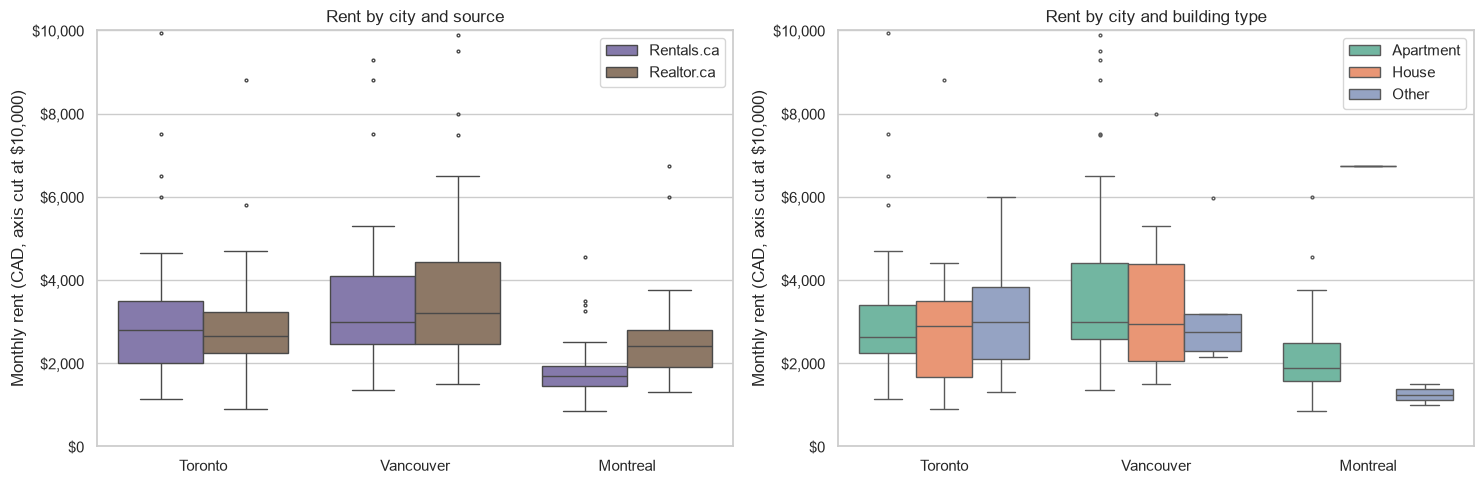

In [14]:
# ============================================================
# 9. SOURCE, BUILDING TYPE AND BATHROOMS
# ============================================================

# --------------RENTALS.CA VS REALTOR.CA-----------------
# If both sources show different rents, the results depend on the source mix.
rent_by_source = (housing.groupby(["city", "bedroom_group", "source"], observed=True)
                  .agg(total_listings = ("monthly_rent_cad", "count"),
                       median_rent = ("monthly_rent_cad", "median")).round(0).unstack("source"))
display(rent_by_source)
save_table(rent_by_source, "14_rent_by_source.csv")

rent_by_city_source = rent_summary(housing, ["city", "source"])
display(rent_by_city_source)
save_table(rent_by_city_source, "15_rent_by_city_source.csv")

# --------------BUILDING TYPE AND BATHROOMS-----------------
rent_by_building = rent_summary(housing, ["city", "building_group"])
print("Rent by city and building type:")
display(rent_by_building)
save_table(rent_by_building, "16_rent_by_city_building.csv")

rent_by_bathrooms = rent_summary(housing, "bathrooms")
print("Rent by number of bathrooms:")
display(rent_by_bathrooms)
save_table(rent_by_bathrooms, "17_rent_by_bathrooms.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=housing, x="city", y="monthly_rent_cad", hue="source", order=CITIES, hue_order=SOURCES,
            palette=SOURCE_COLORS, fliersize=2, ax=axes[0])
axes[0].set_title("Rent by city and source")

sns.boxplot(data=housing, x="city", y="monthly_rent_cad", hue="building_group", order=CITIES,
            hue_order=["Apartment", "House", "Other"], palette="Set2", fliersize=2, ax=axes[1])
axes[1].set_title("Rent by city and building type")

for ax in axes:
    ax.set_ylim(0, RENT_AXIS_LIMIT)
    ax.yaxis.set_major_formatter(dollar_format)
    ax.set_xlabel("")
    ax.set_ylabel(f"Monthly rent (CAD, axis cut at ${RENT_AXIS_LIMIT:,})")
    ax.legend(title="")
save_figure("08_rent_by_source_and_building.png")

Ratings by source (mean, standard deviation and number of different values):


source                      Rentals.ca  Realtor.ca
rating_shopping    mean           8.86        9.26
                   std            0.60        0.72
                   nunique        5.00       26.00
rating_groceries   mean           9.76        9.18
                   std            0.83        0.80
                   nunique        7.00       29.00
rating_restaurants mean           8.86        8.92
                   std            0.55        0.79
                   nunique        4.00       31.00
rating_cafes       mean           9.54        9.21
                   std            1.12        1.06
                   nunique        7.00       32.00
rating_transit     mean           9.00        8.67
                   std            0.00        0.60
                   nunique        1.00       25.00
rating_parks       mean           9.98        9.17
                   std            0.14        1.02
                   nunique        2.00       31.00
rating_wellness    mean           9.57        7.98
                   std            0.96        0.88
                   nunique        6.00       38.00

Realtor.ca listings used for the ratings: 151


,Shopping,Groceries,Restaurants,Cafes,Transit,Parks,Wellness
city,,,,,,,
Toronto,8.84,8.78,8.48,8.83,8.57,9.26,7.70
Vancouver,9.62,9.39,9.33,9.85,8.87,8.64,8.20
Montreal,9.38,9.58,8.95,8.69,8.47,10.00,8.10


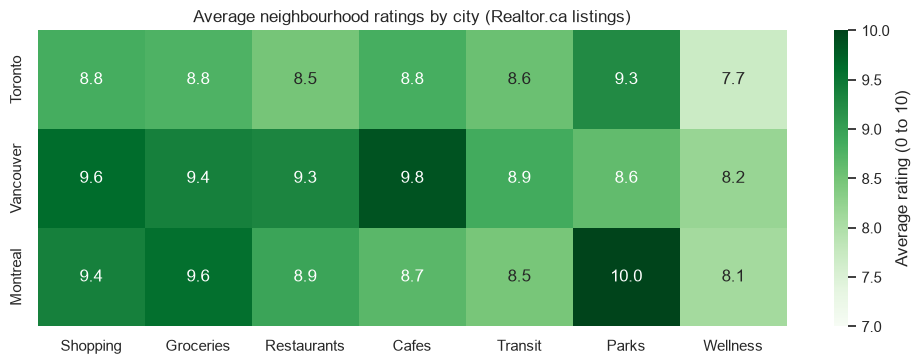

Correlation between each rating and the monthly rent:


,rating,spearman_correlation,p_value,significant_at_5_percent
0,rating_shopping,0.32,6.39e-05,True
1,rating_groceries,0.17,3.39e-02,True
2,rating_restaurants,0.37,3.53e-06,True
3,rating_cafes,0.38,1.99e-06,True
4,rating_transit,0.29,2.53e-04,True
5,rating_parks,-0.14,8.15e-02,False
6,rating_wellness,0.33,2.75e-05,True


In [15]:
# ============================================================
# 10. NEIGHBOURHOOD RATINGS
# ============================================================
# NOTE: The ratings of both websites are not comparable. In Rentals.ca the ratings
# are whole numbers with almost no variation (rating_transit is 9 for every listing),
# while in Realtor.ca they are decimals calculated for each listing.

# --------------RATINGS BY SOURCE-----------------
ratings_by_source = (housing.groupby("source", observed=True)[RATING_COLUMNS]
                     .agg(["mean", "std", "nunique"]).round(2).T)
print("Ratings by source (mean, standard deviation and number of different values):")
display(ratings_by_source)
save_table(ratings_by_source, "18_ratings_by_source.csv")

# --------------RATINGS BY CITY (REALTOR.CA ONLY)-----------------
housing_realtor = housing.loc[housing["source"] == "Realtor.ca"].copy()
print("Realtor.ca listings used for the ratings:", len(housing_realtor))

ratings_by_city = housing_realtor.groupby("city", observed=True)[RATING_COLUMNS].mean().round(2)
ratings_by_city.columns = [column.replace("rating_", "").capitalize() for column in ratings_by_city.columns]
display(ratings_by_city)
save_table(ratings_by_city, "19_ratings_by_city_realtor.csv")

plt.figure(figsize=(10, 3.8))
sns.heatmap(ratings_by_city, annot=True, fmt=".1f", cmap="Greens", vmin=7, vmax=10, cbar_kws={"label": "Average rating (0 to 10)"})
plt.title("Average neighbourhood ratings by city (Realtor.ca listings)")
plt.xlabel("")
plt.ylabel("")
save_figure("09_heatmap_ratings_by_city.png")

# --------------RATINGS VS RENT (REALTOR.CA ONLY)-----------------
rating_results = []
for rating in RATING_COLUMNS:
    correlation, p_value = stats.spearmanr(housing_realtor[rating], housing_realtor["monthly_rent_cad"])
    rating_results.append({"rating": rating,
                           "spearman_correlation": round(correlation, 2),
                           "p_value": f"{p_value:.2e}",
                           "significant_at_5_percent": p_value < 0.05})
rating_correlation = pd.DataFrame(rating_results)
print("Correlation between each rating and the monthly rent:")
display(rating_correlation)
save_table(rating_correlation, "20_correlation_ratings_rent.csv", index=False)

In [16]:
# ============================================================
# 11. PRELIMINARY STATISTICAL TESTS
# ============================================================
# Kruskal-Wallis is used because rents are skewed and groups have different sizes.
# p-value < 0.05 means at least one group has a different rent distribution.
test_results = []

test_results.append(kruskal_test(housing, "city", "Between cities (all listings)"))
test_results.append(kruskal_test(housing, "bedroom_group", "Between bedroom groups (all cities)"))

for bedroom_group in BEDROOM_GROUPS:
    test_results.append(kruskal_test(housing.loc[housing["bedroom_group"] == bedroom_group], "city", f"Between cities | {bedroom_group}"))

for city in CITIES:
    test_results.append(kruskal_test(housing.loc[housing["city"] == city], "bedroom_group", f"Between bedroom groups | {city}"))

for city in CITIES:
    test_results.append(kruskal_test(housing.loc[housing["city"] == city], "source", f"Between sources | {city}"))

kruskal_report = pd.DataFrame(test_results)
kruskal_report["significant_at_5_percent"] = kruskal_report["p_value"] < 0.05
kruskal_report["p_value"] = kruskal_report["p_value"].apply(lambda x: f"{x:.2e}")
display(kruskal_report)
save_table(kruskal_report, "21_kruskal_wallis_tests.csv", index=False)

,comparison,groups,total_listings,h_statistic,p_value,significant_at_5_percent
0,Between cities (all listings),3,313,69.49,8.16e-16,True
1,Between bedroom groups (all cities),5,313,104.95,8.67e-22,True
2,Between cities | Studio,3,22,15.63,4.04e-04,True
3,Between cities | 1 bedroom,3,100,41.62,9.19e-10,True
4,Between cities | 2 bedrooms,3,116,40.41,1.67e-09,True
5,Between cities | 3 bedrooms,3,52,24.79,4.13e-06,True
6,Between cities | 4+ bedrooms,2,23,2.73,9.86e-02,False
7,Between bedroom groups | Toronto,5,114,55.05,3.18e-11,True
8,Between bedroom groups | Vancouver,5,116,57.69,8.84e-12,True
9,Between bedroom groups | Montreal,4,83,38.08,2.72e-08,True


In [17]:
# ============================================================
# 12. SAVE DATASET AND EDA SUMMARY
# ============================================================
housing.to_csv(output_folder / "housing_eda_dataset.csv", index=False, encoding="utf-8-sig")

one_bedroom = housing.loc[housing["bedroom_group"] == "1 bedroom"]
two_bedrooms = housing.loc[housing["bedroom_group"] == "2 bedrooms"]
rent_one_bedroom = one_bedroom.groupby("city", observed=True)["monthly_rent_cad"].median()
rent_two_bedrooms = two_bedrooms.groupby("city", observed=True)["monthly_rent_cad"].median()
smallest_group = rent_by_city_bedrooms["total_listings"].idxmin()

# Overall EDA Summary
eda_summary = pd.DataFrame({"Metric": ["Listings used in the EDA",
                                       "Listings Toronto",
                                       "Listings Vancouver",
                                       "Listings Montreal",
                                       "Overall median rent",
                                       "Median rent Toronto",
                                       "Median rent Vancouver",
                                       "Median rent Montreal",
                                       "Median rent 1 bedroom Toronto",
                                       "Median rent 1 bedroom Vancouver",
                                       "Median rent 1 bedroom Montreal",
                                       "Median rent 2 bedrooms Toronto",
                                       "Median rent 2 bedrooms Vancouver",
                                       "Median rent 2 bedrooms Montreal",
                                       "Smallest group (city | bedrooms)",
                                       "Listings flagged as rent outliers"],
                            "Value": [len(housing),
                                      rent_by_city.loc["Toronto", "total_listings"],
                                      rent_by_city.loc["Vancouver", "total_listings"],
                                      rent_by_city.loc["Montreal", "total_listings"],
                                      round(housing["monthly_rent_cad"].median()),
                                      rent_by_city.loc["Toronto", "median_rent"],
                                      rent_by_city.loc["Vancouver", "median_rent"],
                                      rent_by_city.loc["Montreal", "median_rent"],
                                      rent_one_bedroom.loc["Toronto"],
                                      rent_one_bedroom.loc["Vancouver"],
                                      rent_one_bedroom.loc["Montreal"],
                                      rent_two_bedrooms.loc["Toronto"],
                                      rent_two_bedrooms.loc["Vancouver"],
                                      rent_two_bedrooms.loc["Montreal"],
                                      f"{smallest_group[0]} | {smallest_group[1]}",
                                      housing["rent_outlier"].sum()]})
display(eda_summary)
save_table(eda_summary, "22_eda_summary.csv", index=False)

print("Figures saved in:", figures_folder.relative_to(PROJECT_ROOT))
print("Tables saved in:", tables_folder.relative_to(PROJECT_ROOT))
print("Final dataset shape:", housing.shape)

,Metric,Value
0,Listings used in the EDA,313
1,Listings Toronto,114
2,Listings Vancouver,116
3,Listings Montreal,83
4,Overall median rent,2600
5,Median rent Toronto,"2,772.00"
6,Median rent Vancouver,"3,000.00"
7,Median rent Montreal,"1,890.00"
8,Median rent 1 bedroom Toronto,"2,016.00"
9,Median rent 1 bedroom Vancouver,"2,600.00"


Figures saved in: output/eda_housing/figures
Tables saved in: output/eda_housing/tables
Final dataset shape: (313, 25)
